### Estudio de caso de deserción de empleados de recursos humanos
### Contexto :
Una empresa multinacional busca reducir los costos de retención de personal sin afectar el talento clave. Para ello, se propone identificar empleados con alto riesgo de abandonar la organización y dirigir incentivos únicamente a ese grupo. Como científico de datos del área de Recursos Humanos, tu tarea es analizar los factores asociados a la deserción y predecir la probabilidad de abandono de cada empleado.

### Objetivo :

Analizar los datos proporcionados para identificar los diferentes factores que impulsan la deserción y construir un modelo que pueda ayudar a predecir la deserción.


### Conjunto de datos:
Los datos contienen detalles demográficos, métricas relacionadas con el trabajo y un indicador de deserción.

* EmployeeNumber - Identificador del empleado
* Attrition - ¿El empleado ha renunciado?
* Age - Edad del empleado
* BusinessTravel - Compromisos de viaje para el trabajo
* DailyRate - Descripción de datos no disponible
* Department - Departmento del empleado
* DistanceFromHome - Distancia del trabajo a casa (en km)
* Education - 1-Bow College, 2-College, 3-Bachelor, 4-Master,5-Doctor
* EducationField - Campo de educación
* EmployeeCount - Recuento de empleados
* EnvironmentSatisfaction - 1-Bajo, 2-Medio, 3-Alto, 4-Muy Alto
* Gender - Género del empleado
* HourlyRate - Descripción de datos no disponible
* JobInvolvement - 1-Low, 2-Medium, 3-High, 4-Very High
* JobLevel - Nivel de trabajo (1 to 5)
* JobRole - Roles de trabajo
* JobSatisfaction - 1-Bajo, 2-Medio, 3-Alto, 4-Muy Alto
* MaritalStatus - Estado civil
* MonthlyIncome - Salario mensual
* MonthlyRate - Descripción de datos no disponible
* NumCompaniesWorked - Número de empresas en las que ha trabajado
* Over18 - ¿Mayores de 18 años?
* OverTime - ¿Horas extras?
* PercentSalaryHike - Porcentaje de aumento del salario en el último año
* PerformanceRating - 1-Bajo, 2-Bueno, 3-Excelente, 4-Excelente
* RelationshipSatisfaction - 1-Bajo, 2-Medio, 3-Alto, 4-Muy Alto
* StandardHours - Horas estándar
* StockOptionLevel - Nivel óptimo de stock
* TotalWorkingYears - Total de años trabajados
* TrainingTimesLastYear - Número de capacitaciones a las que asistió el año pasado
* WorkLifeBalance - 1-Bajo, 2-Bueno, 3-Excelente, 4-Excelente
* YearsAtCompany - Años en la compañía
* YearsInCurrentRole - Años en el puesto actual
* YearsSinceLastPromotion - Años desde la última promoción
* YearsWithCurrManager - Años con el gerente actual

## **Importación de las bibliotecas y descripción general del conjunto de datos**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# To scale the data using z-score
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

# Algorithms to use
from sklearn.linear_model import LogisticRegression

from sklearn.svm import SVC

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import BaggingClassifier

from sklearn.ensemble import RandomForestClassifier

# Metrics to evaluate the model
from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_curve,recall_score
from sklearn import tree


# For tuning the model
from sklearn.model_selection import GridSearchCV

# To ignore warnings
import warnings
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
! ls -la drive/MyDrive/datos

total 495
drwx------ 2 root root   4096 Oct  6 17:52 .
drwx------ 4 root root   4096 Oct 13 17:27 ..
-rw------- 1 root root 498226 Oct  6 17:52 HR_Employee_Attrition_Dataset.xlsx


### **Cargando el conjunto de datos**

In [ ]:
# Loading the dataset
df = pd.read_excel('drive/MyDrive/datos/HR_Employee_Attrition_Dataset.xlsx')

In [ ]:
df.head()

,EmployeeNumber,Attrition,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,1,Yes,41,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,...,1,80,0,8,0,1,6,4,0,5
1,2,No,49,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,...,4,80,1,10,3,3,10,7,1,7
2,3,Yes,37,Travel_Rarely,1373,Research & Development,2,2,Other,4,...,2,80,0,7,3,3,0,0,0,0
3,4,No,33,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,...,3,80,0,8,3,3,8,7,3,0
4,5,No,27,Travel_Rarely,591,Research & Development,2,1,Medical,1,...,4,80,1,6,3,3,2,2,2,2


### **Comprobar la información del conjunto de datos**

In [ ]:
# Let us see the info of the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2940 entries, 0 to 2939
Data columns (total 34 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   EmployeeNumber            2940 non-null   int64 
 1   Attrition                 2940 non-null   object
 2   Age                       2940 non-null   int64 
 3   BusinessTravel            2940 non-null   object
 4   DailyRate                 2940 non-null   int64 
 5   Department                2940 non-null   object
 6   DistanceFromHome          2940 non-null   int64 
 7   Education                 2940 non-null   int64 
 8   EducationField            2940 non-null   object
 9   EnvironmentSatisfaction   2940 non-null   int64 
 10  Gender                    2940 non-null   object
 11  HourlyRate                2940 non-null   int64 
 12  JobInvolvement            2940 non-null   int64 
 13  JobLevel                  2940 non-null   int64 
 14  JobRole                 

**Observaciones:**

- Hay **2940 observaciones y 34 columnas** en el conjunto de datos.
- Todas las columnas tienen 2940 valores no nulos, es decir, **no faltan valores en los datos.**

**Valores únicos en cada columna**

In [ ]:
# Checar los valores únicos en cada columna
df.nunique()

,0
EmployeeNumber,2940
Attrition,2
Age,43
BusinessTravel,3
DailyRate,886
Department,3
DistanceFromHome,29
Education,5
EducationField,6
EnvironmentSatisfaction,4


**Observaciones:**

- **El número de empleado es un identificador** único para cada empleado y **podemos eliminar esta columna** ya que no agregaría ningún valor a nuestro análisis.
- **Over18 y StandardHours tienen solo 1 valor único.** Estas columnas no agregarán ningún valor a nuestro modelo, por lo tanto, podemos eliminarlas.
- Over18 y StandardHours tienen solo 1 valor único. Podemos eliminar estas columnas ya que no agregarán ningún valor a nuestro análisis.
- Sobre la base del número de valores únicos en cada columna y la descripción de los datos, podemos identificar las columnas continuas y categóricas en los datos.

**Eliminar las columnas mencionadas anteriormente** y definamos listas para columnas numéricas y categóricas para explorarlas por separado.

In [ ]:
# Eliminar columnas
df=df.drop(['EmployeeNumber','Over18','StandardHours'],axis=1)

In [ ]:
# Variables numericas
num_cols=['DailyRate','Age','DistanceFromHome','MonthlyIncome','MonthlyRate','PercentSalaryHike','TotalWorkingYears',
          'YearsAtCompany','NumCompaniesWorked','HourlyRate',
          'YearsInCurrentRole','YearsSinceLastPromotion','YearsWithCurrManager','TrainingTimesLastYear']

# VAriables categegoricas
cat_cols= ['Attrition','OverTime','BusinessTravel', 'Department','Education', 'EducationField','JobSatisfaction','EnvironmentSatisfaction','WorkLifeBalance',
           'StockOptionLevel','Gender', 'PerformanceRating', 'JobInvolvement','JobLevel', 'JobRole', 'MaritalStatus','RelationshipSatisfaction']

## **Análisis exploratorio de datos y preprocesamiento de datos**

### **Análisis univariado de columnas numéricas**

In [ ]:
# Estadisticas Básicas
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
DailyRate,2940.0,802.485714,403.440447,102.0,465.0,802.0,1157.0,1499.0
Age,2940.0,36.923810,9.133819,18.0,30.0,36.0,43.0,60.0
DistanceFromHome,2940.0,9.192517,8.105485,1.0,2.0,7.0,14.0,29.0
MonthlyIncome,2940.0,6502.931293,4707.155770,1009.0,2911.0,4919.0,8380.0,19999.0
MonthlyRate,2940.0,14313.103401,7116.575021,2094.0,8045.0,14235.5,20462.0,26999.0
PercentSalaryHike,2940.0,15.209524,3.659315,11.0,12.0,14.0,18.0,25.0
TotalWorkingYears,2940.0,11.279592,7.779458,0.0,6.0,10.0,15.0,40.0
YearsAtCompany,2940.0,7.008163,6.125483,0.0,3.0,5.0,9.0,40.0
NumCompaniesWorked,2940.0,2.693197,2.497584,0.0,1.0,2.0,4.0,9.0
HourlyRate,2940.0,65.891156,20.325969,30.0,48.0,66.0,84.0,100.0


**Observaciones:**

- **La edad promedio de los empleados es de alrededor de 37 años**. Tiene un rango alto, de 18 años a 60 años, lo que indica una buena diversidad de edad en la organización.
- **Al menos el 50% de los empleados viven en un radio de 7 KM** de la organización. Sin embargo, existen algunos valores extremos, dado que el valor máximo es de 29 km.
- **El ingreso promedio mensual de un empleado es de USD 6500.** Tiene un alto rango de valores de 1K-20K USD, lo cual es de esperar para la distribución de ingresos de cualquier organización. Hay una gran diferencia entre el valor del tercer cuartil (alrededor de USD 8400) y el valor máximo (casi USD 20 000), lo que demuestra que **las personas con mayores ingresos de la empresa tienen un ingreso desproporcionadamente alto** en comparación con el resto de los empleados. Nuevamente, esto es bastante común en la mayoría de las organizaciones.
- **El aumento salarial promedio de un empleado es de alrededor del 15 %.** Al menos el 50 % de los empleados obtuvo un aumento salarial del 14 % o menos, siendo el aumento salarial máximo del 25 %.
- La media de años de vinculación de un empleado a la empresa es de 7.
- **En promedio, la cantidad de años desde que un empleado obtuvo una promoción es ~2.19**. La mayoría de los empleados han sido promovidos desde el último año.

**Distribuciones de las variables**

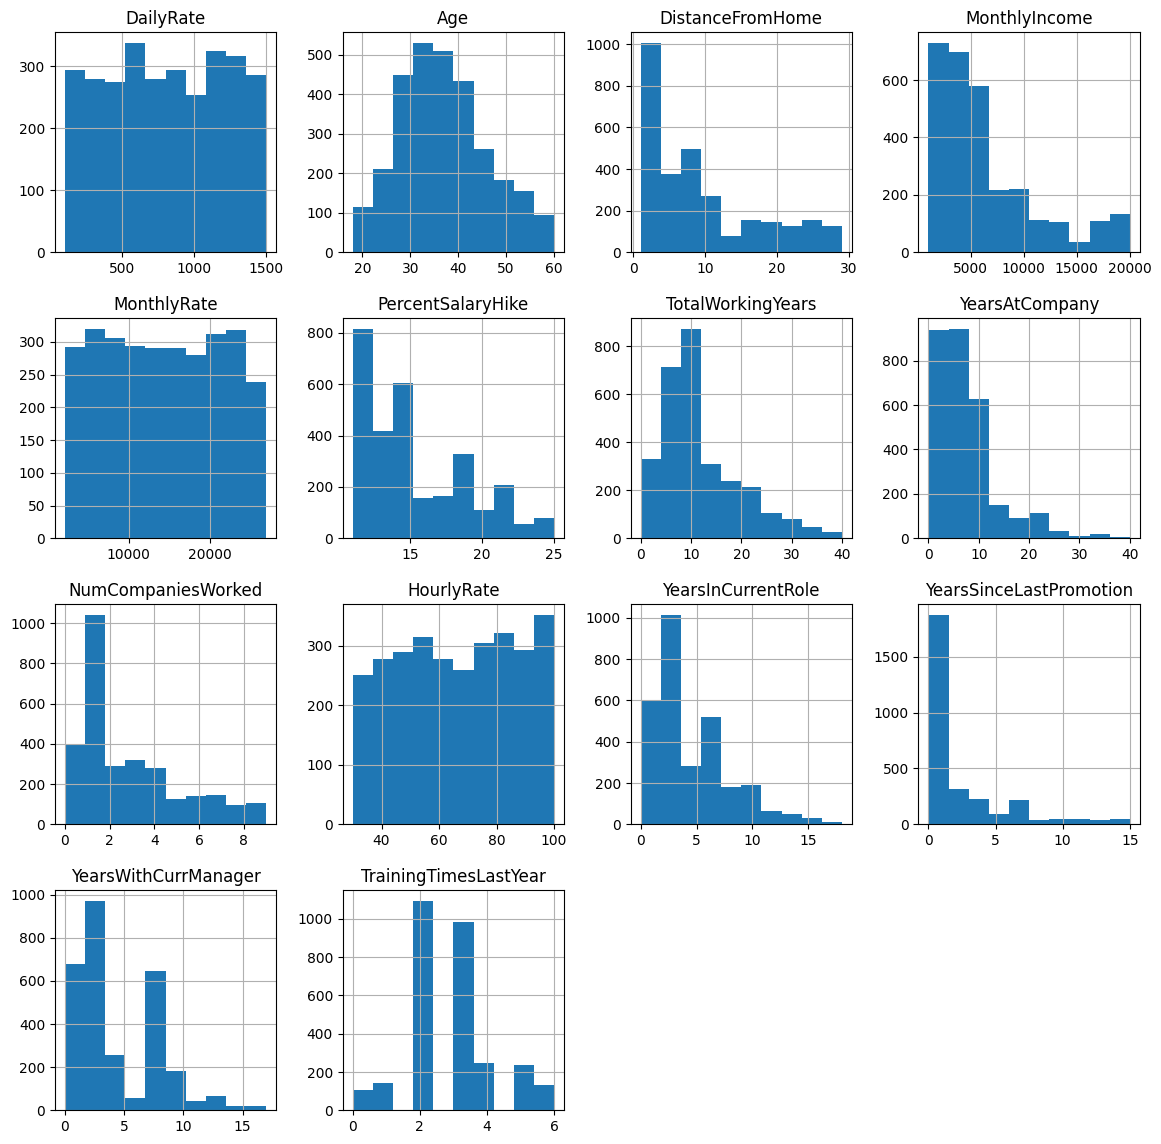

In [ ]:
# Crear histogramas
df[num_cols].hist(figsize=(14,14))
plt.show()

**Observaciones:**

- **La distribución por edades es cercana a una distribución normal** con la mayoría de los empleados entre 25 y 50 años.

- **El porcentaje de aumento salarial está sesgado a la derecha**, lo que implica que los empleados obtienen aumentos menores.

- **MonthlyIncome y TotalWorkingYears están sesgados a la derecha**, lo que indica que la mayoría de los trabajadores se encuentran en puestos de nivel inicial/medio en la organización.

- **DistanceFromHome también tiene una distribución sesgada a la derecha**, lo que significa que la mayoría de los empleados viven cerca del trabajo, pero hay algunos que viven más lejos.

- **En promedio, un empleado ha trabajado en 2,5 empresas.** La mayoría de los empleados han trabajado en solo 1 empresa.

- **La distribución de la variable YearsAtCompany muestra una buena proporción de trabajadores con más de 10 años**, lo que indica un número significativo de empleados leales a la organización.

- **La distribución YearsInCurrentRole tiene tres picos en 0, 2 y 7.** Hay algunos empleados que han permanecido en el mismo rol durante 15 años o más.

- **La distribución de la variable YearsSinceLastPromotion indica que algunos empleados no han recibido un ascenso en 10-15 años y todavía están trabajando en la organización.** Se supone que estos empleados son empleados con mucha experiencia laboral en la alta gerencia roles, como cofundadores, empleados de C-suite, etc.

- Las distribuciones de TarifaDiaria, TarifaHora y TarifaMensual parecen ser uniformes y no brindan mucha información. Podría ser que la tarifa diaria se refiera a los ingresos obtenidos por día adicional trabajado, mientras que la tarifa por hora podría referirse al mismo concepto que se aplica a las horas extra trabajadas por día. Dado que estas tasas tienden a ser muy similares para varios empleados en el mismo departamento, eso explica la distribución uniforme que muestran.

### **Análisis univariante para variables categóricas**

In [ ]:
# Imprimir el % de valores por cada categoria
for i in cat_cols:
    print(df[i].value_counts(normalize=True))
    print(df[i].value_counts())
    print('*'*40)

Attrition
No     0.838776
Yes    0.161224
Name: proportion, dtype: float64
Attrition
No     2466
Yes     474
Name: count, dtype: int64
****************************************
OverTime
No     0.717007
Yes    0.282993
Name: proportion, dtype: float64
OverTime
No     2108
Yes     832
Name: count, dtype: int64
****************************************
BusinessTravel
Travel_Rarely        0.709524
Travel_Frequently    0.188435
Non-Travel           0.102041
Name: proportion, dtype: float64
BusinessTravel
Travel_Rarely        2086
Travel_Frequently     554
Non-Travel            300
Name: count, dtype: int64
****************************************
Department
Research & Development    0.653741
Sales                     0.303401
Human Resources           0.042857
Name: proportion, dtype: float64
Department
Research & Development    1922
Sales                      892
Human Resources            126
Name: count, dtype: int64
****************************************
Education
3    0.389116
4    0.2

**Observaciones:**

- **La tasa de deserción de empleados es del 16%.**
- **Alrededor del 28 % de los empleados trabajan horas extras.** Este número parece estar en el lado superior y podría indicar una vida laboral estresada por parte de los empleados.
- El 71% de los empleados ha viajado pocas veces, mientras que alrededor del 19% tiene que viajar con frecuencia.
- Alrededor del 73% de los empleados provienen de una formación académica en los campos de Ciencias de la Vida y Medicina.
- Más del 65% de los empleados trabajan en el departamento de Investigación y Desarrollo de la organización.
- **Cerca del 40% de los empleados tienen una satisfacción laboral y ambiental baja (1) o media-baja (2)** en la organización, lo que indica que la moral de la empresa parece estar algo baja.
- **Más del 30% de los empleados muestran una implicación laboral baja (1) a media-baja (2).**
- Más del 80% de los empleados no tienen o tienen muy pocas opciones sobre acciones.
- **En términos de calificaciones de desempeño, ninguno de los empleados tiene una calificación inferior a 3 (excelente).** Alrededor del 85% de los empleados tienen una calificación de desempeño igual a 3 (excelente), mientras que el resto tiene una calificación de 4 (sobresaliente). Esto podría significar que la mayoría de los empleados tienen un desempeño superior, o el escenario más probable es que la organización podría ser muy indulgente con su proceso de evaluación del desempeño.

### **Análisis bivariado y multivariado**
Observar cómo se relaciona la tasa de deserción con otras variables categóricas.

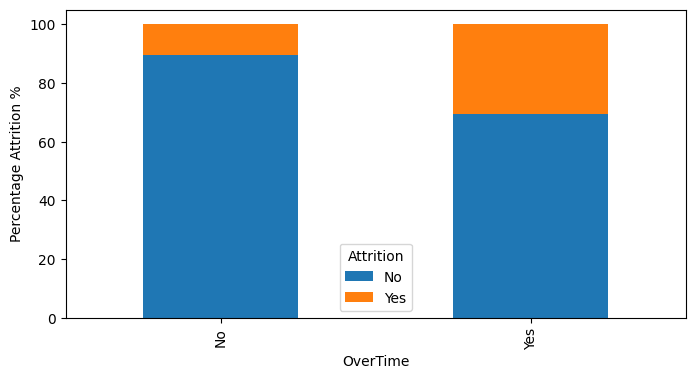

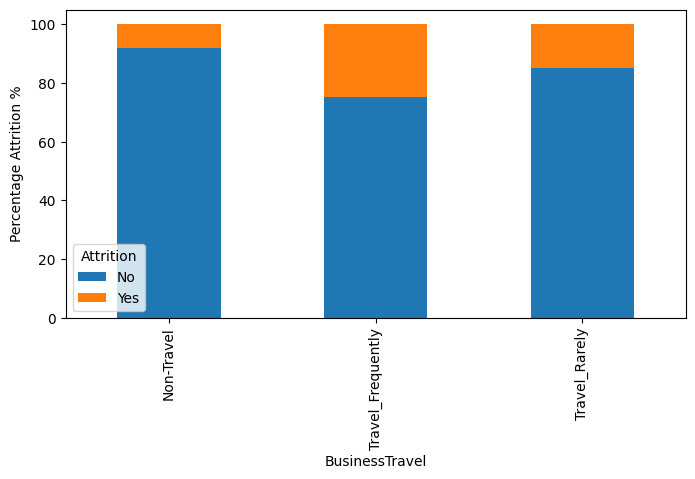

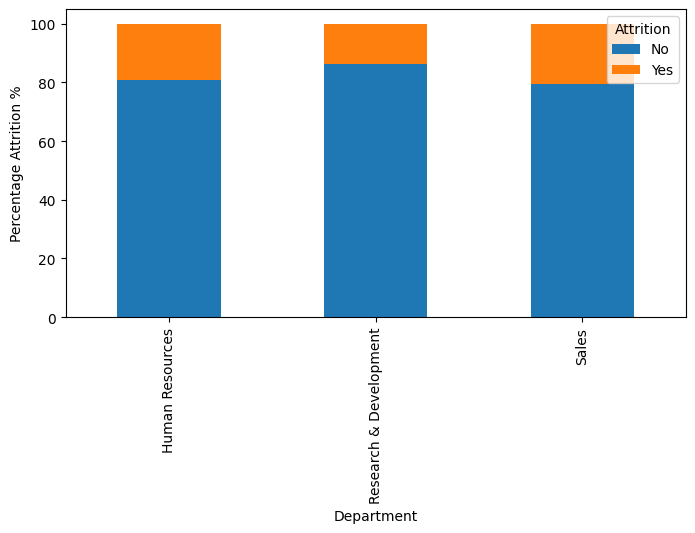

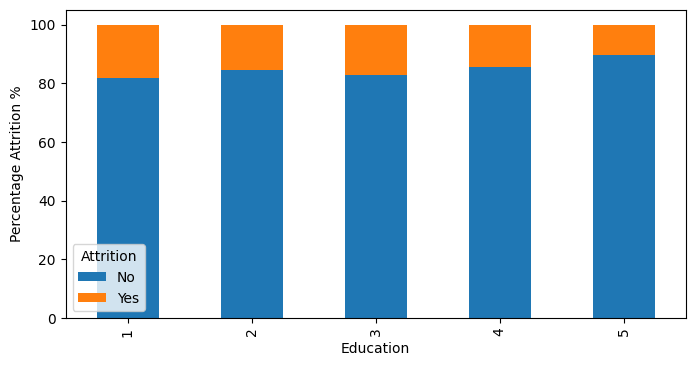

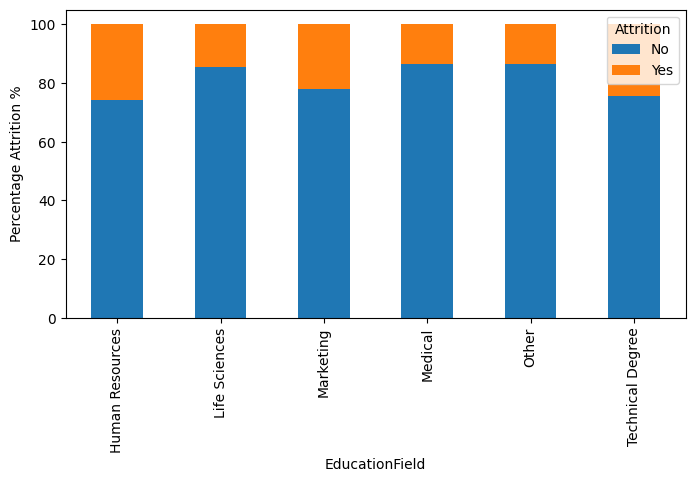

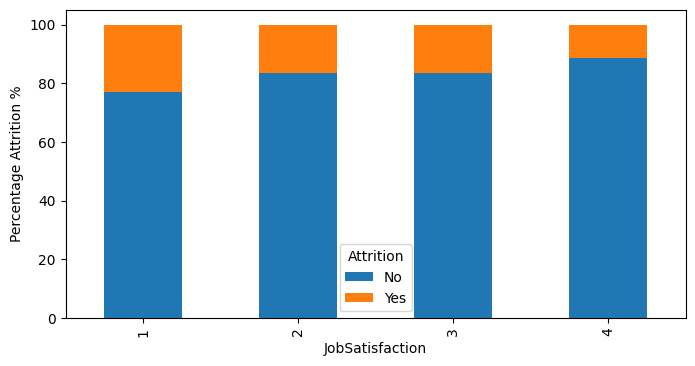

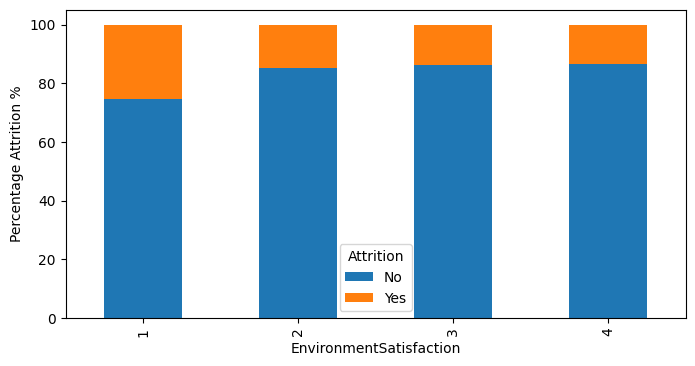

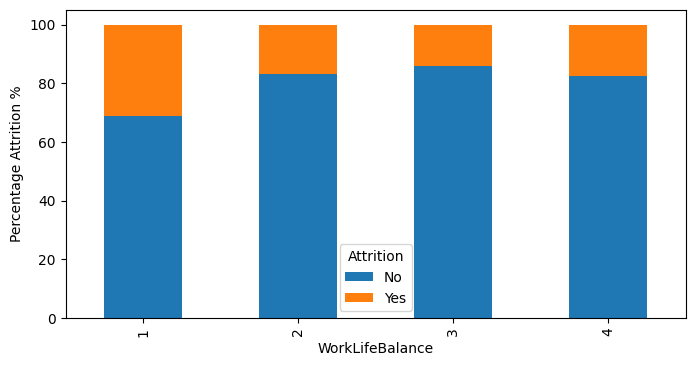

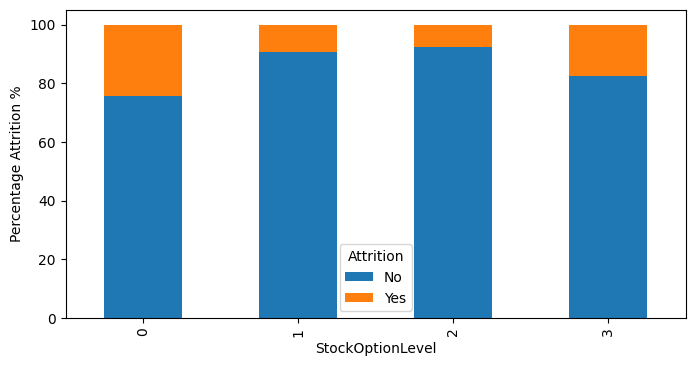

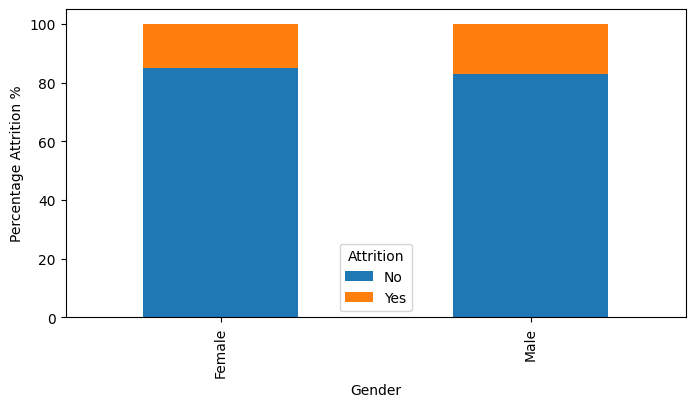

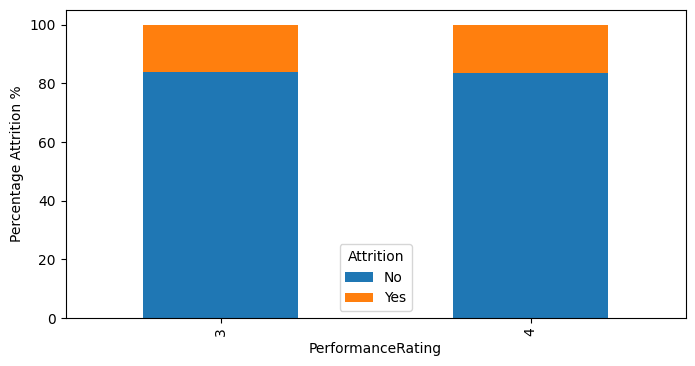

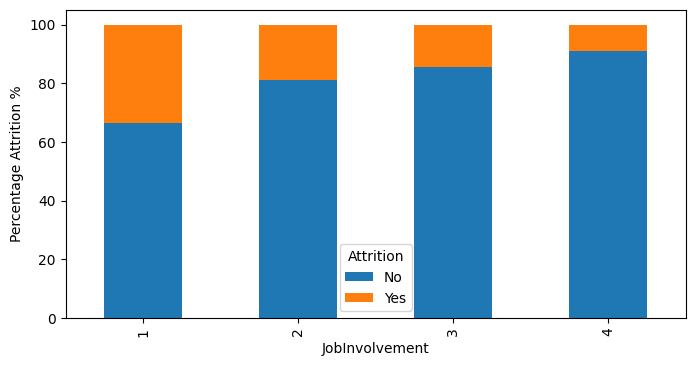

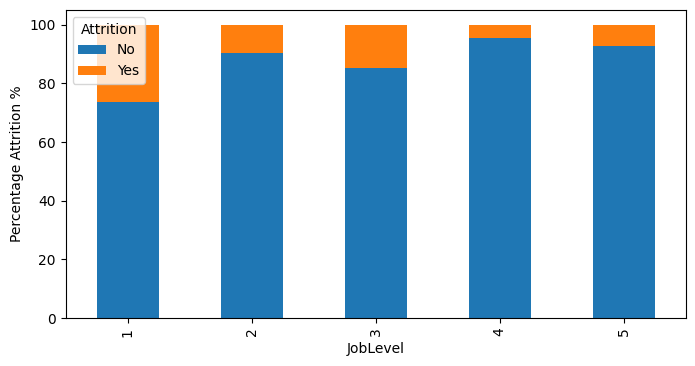

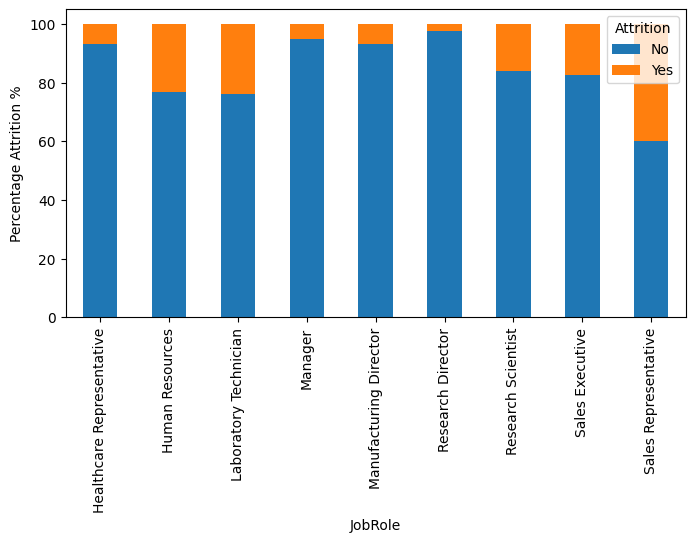

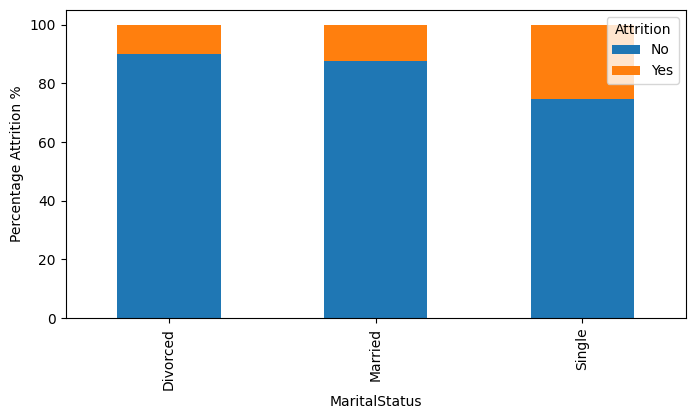

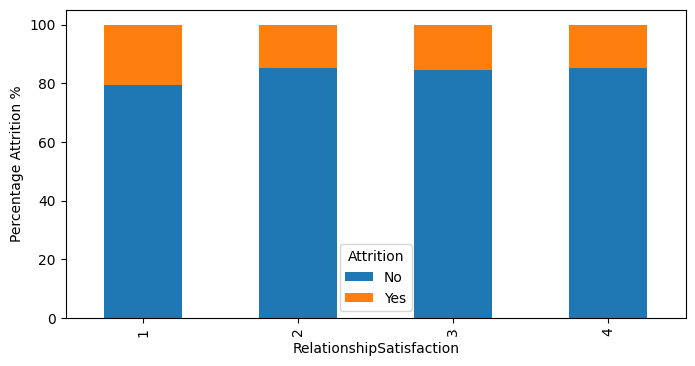

In [ ]:
for i in cat_cols:
    if i!='Attrition':
        (pd.crosstab(df[i],df['Attrition'],normalize='index')*100).plot(kind='bar',figsize=(8,4),stacked=True)
        plt.ylabel('Percentage Attrition %')

**Observaciones:**
    
- **Los empleados que trabajan horas extra tienen más de un 30 % de posibilidades de deserción**,
lo cual es muy alto en comparación con el 10% de probabilidad de abandono de los empleados que no trabajan horas extra.
- Como se vio anteriormente, la mayoría de los empleados trabajan para el departamento de I+D. La posibilidad de desgaste allí es ~ 15%
- **Los empleados que trabajan como representantes de ventas tienen una tasa de deserción de alrededor del 40 %** mientras que los RRHH y los técnicos tienen una tasa de deserción de alrededor del 25 %. Los departamentos de ventas y recursos humanos tienen tasas de deserción más altas en comparación con un departamento académico como Investigación y Desarrollo, una observación que tiene sentido intuitivo si se tienen en cuenta las diferencias en esos perfiles de trabajo. La naturaleza de alta presión y basada en incentivos de los roles de Ventas y Marketing puede estar contribuyendo a sus tasas de deserción más altas.
- **Cuanto menor es la participación laboral del empleado, mayores parecen ser sus posibilidades de deserción, y los empleados con participación laboral calificada como 1 pierden un 35 %.** La razón de esto podría ser que los empleados con menor participación laboral pueden sentirse excluidos o menos valorados y ya han comenzado a explorar nuevas opciones, lo que lleva a una mayor tasa de deserción.
- **Los empleados en un nivel de trabajo más bajo también pierden más,** con los empleados de JobLevel calificados como 1 que muestran una probabilidad de abandono de casi el 25 %. Estos pueden ser empleados jóvenes que tienden a explorar más opciones en las etapas iniciales de sus carreras.
- **Una calificación baja de equilibrio entre la vida laboral y personal claramente lleva a los empleados a la deserción**, el 30 % de los que están en la categoría 1 muestra la deserción.

**Veamos la relación entre la deserción y las variables numéricas**

In [ ]:
# promedio de las variables numericas por attrition
df.groupby(['Attrition'])[num_cols].mean()

,DailyRate,Age,DistanceFromHome,MonthlyIncome,MonthlyRate,PercentSalaryHike,TotalWorkingYears,YearsAtCompany,NumCompaniesWorked,HourlyRate,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,TrainingTimesLastYear
Attrition,,,,,,,,,,,,,,
No,812.504461,37.561233,8.915653,6832.739659,14265.779400,15.231144,11.862936,7.369019,2.645580,65.952149,4.484185,2.234388,4.367397,2.832928
Yes,750.362869,33.607595,10.632911,4787.092827,14559.308017,15.097046,8.244726,5.130802,2.940928,65.573840,2.902954,1.945148,2.852321,2.624473


**Observaciones:**
- **Los empleados que dejan la empresa tienen un ingreso promedio casi un 30 % más bajo y un 30 % menos de experiencia laboral que los que no lo hacen.** Estos podrían ser los empleados que buscan explorar nuevas opciones y/o aumentar su salario con un cambio de compañía.
- **Los empleados que muestran deserción también tienden a vivir un 16 % más lejos de la oficina que los que no lo están**. El viaje más largo hacia y desde el trabajo podría significar que tienen que gastar más tiempo/dinero todos los días, y esto podría generar insatisfacción laboral y querer dejar la organización.

### **Relación entre diferentes variables numéricas**

<Axes: >

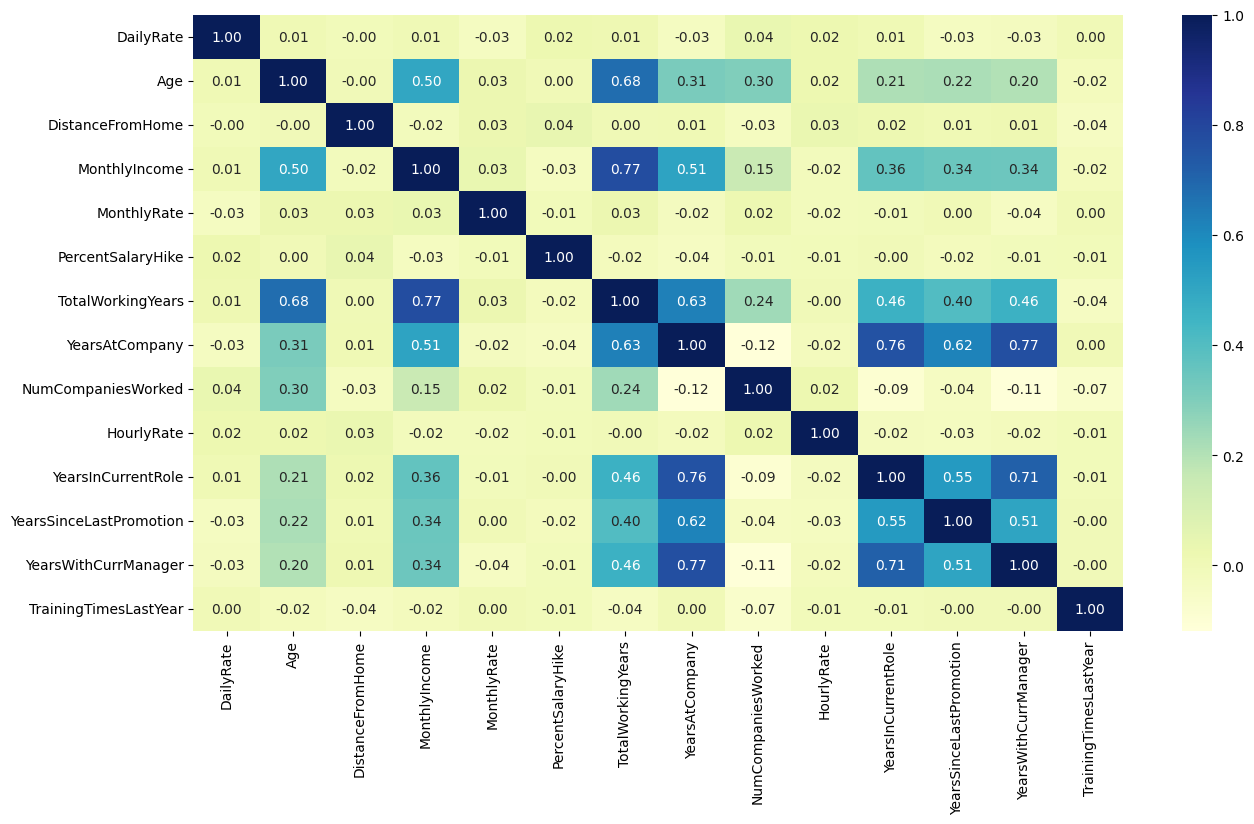

In [ ]:
# Correlacion entre variables numricas
plt.figure(figsize=(15,8))
sns.heatmap(df[num_cols].corr(),annot=True, fmt='0.2f', cmap='YlGnBu')

**Observaciones:**

- **La experiencia laboral total, los ingresos mensuales, los años en la empresa y los años con el gerente actual están altamente correlacionados entre sí y con la edad del empleado**, lo cual es fácil de entender ya que estas variables muestran un aumento con la edad para la mayoría de los empleados .
- Los años en la empresa y los años en el puesto actual se correlacionan con los años transcurridos desde la última promoción, lo que significa que la empresa no está dando promociones en el momento adecuado.

**Ahora hemos explorado nuestros datos. Construyamos el modelo**

## **Construcción de modelos - Enfoque**

1. Preparación de datos.
2. Divida los datos en un conjunto de entrenamiento y prueba.
3. Construya un modelo sobre los datos del entrenamiento.
4. Ajuste el modelo si es necesario.
5. Pruebe los datos en el equipo de prueba.

### **Preparación de datos**

**Creación de variables ficticias para variables categóricas**

In [ ]:
# Crear variables dummy
to_get_dummies_for = ['BusinessTravel', 'Department','Education', 'EducationField','EnvironmentSatisfaction', 'Gender',  'JobInvolvement','JobLevel', 'JobRole', 'MaritalStatus' ]

df = pd.get_dummies(data = df, columns = to_get_dummies_for, drop_first = True)

# Mapear variables
dict_OverTime = {'Yes': 1, 'No':0}
dict_attrition = {'Yes': 1, 'No': 0}


df['OverTime'] = df.OverTime.map(dict_OverTime)
df['Attrition'] = df.Attrition.map(dict_attrition)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2940 entries, 0 to 2939
Data columns (total 55 columns):
 #   Column                             Non-Null Count  Dtype
---  ------                             --------------  -----
 0   Attrition                          2940 non-null   int64
 1   Age                                2940 non-null   int64
 2   DailyRate                          2940 non-null   int64
 3   DistanceFromHome                   2940 non-null   int64
 4   HourlyRate                         2940 non-null   int64
 5   JobSatisfaction                    2940 non-null   int64
 6   MonthlyIncome                      2940 non-null   int64
 7   MonthlyRate                        2940 non-null   int64
 8   NumCompaniesWorked                 2940 non-null   int64
 9   OverTime                           2940 non-null   int64
 10  PercentSalaryHike                  2940 non-null   int64
 11  PerformanceRating                  2940 non-null   int64
 12  RelationshipSatisfac

In [ ]:
df

,Attrition,Age,DailyRate,DistanceFromHome,HourlyRate,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,...,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single
0,1,41,1102,1,94,4,5993,19479,8,1,...,False,False,False,False,False,False,True,False,False,True
1,0,49,279,8,61,2,5130,24907,1,0,...,False,False,False,False,False,True,False,False,True,False
2,1,37,1373,2,92,3,2090,2396,6,1,...,False,True,False,False,False,False,False,False,False,True
3,0,33,1392,3,56,3,2909,23159,1,1,...,False,False,False,False,False,True,False,False,True,False
4,0,27,591,2,40,2,3468,16632,9,0,...,False,True,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2935,0,36,884,23,41,4,2571,12290,4,0,...,False,True,False,False,False,False,False,False,True,False
2936,0,39,613,6,42,1,9991,21457,4,0,...,False,False,False,False,False,False,False,False,True,False
2937,0,27,155,4,87,2,6142,5174,1,1,...,False,False,False,True,False,False,False,False,True,False
2938,0,49,1023,2,63,2,5390,13243,2,0,...,False,False,False,False,False,False,True,False,True,False


**Separando las variables independientes (X) y la variable dependiente (Y)**

In [ ]:
# Separar la variable objetivos de las demas

Y= df.Attrition
X= df.drop(columns = ['Attrition'])

**Dividir los datos en 70 % de entrenamiento y 30 % de conjunto de prueba**

Algunos problemas de clasificación pueden exhibir un gran desequilibrio en la distribución de las clases objetivo: por ejemplo, podría haber varias veces más muestras negativas que muestras positivas. En tales casos, se recomienda utilizar la técnica de **muestreo estratificado** para garantizar que las frecuencias de clase relativas se conserven aproximadamente en cada entrenamiento y pliegue de validación.

In [ ]:
# Separar los datos en train y test
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size = 0.3, random_state = 1, stratify = Y)

In [ ]:
print(y_train.value_counts(normalize=True))

Attrition
0    0.838678
1    0.161322
Name: proportion, dtype: float64


In [ ]:
print(y_test.value_counts(normalize=True))

Attrition
0    0.839002
1    0.160998
Name: proportion, dtype: float64


In [ ]:
y_test

,Attrition
2880,0
1946,0
1678,0
1163,0
1842,0
...,...
902,0
629,0
999,0
309,0


### **Escalando los datos**

Las variables independientes en este conjunto de datos tienen diferentes escalas. Cuando las características tienen escalas diferentes entre sí, existe la posibilidad de que se otorgue una mayor ponderación a las características que tienen una magnitud más alta, y dominarán sobre otras características cuyos cambios de magnitud pueden ser menores pero cuyos cambios porcentuales pueden ser igual de significativos o incluso más grande. Esto afectará el rendimiento de nuestro algoritmo de aprendizaje automático y no queremos que nuestro algoritmo esté sesgado hacia una característica.

La solución a este problema es **Feature Scaling**, es decir, escalar el conjunto de datos para dar a cada variable transformada una escala comparable.

Los modelos basados ​​en árboles como **Decision Trees** y **Random Forest** no requieren que se realice el escalado de características, ya que no son sensibles a la variación en los datos.

Escalaremos los datos para **Regresión logística** y **SVM**. Usaremos el método **Standard Scaler**, que centra y escala el conjunto de datos usando el Z-Score. Estandariza las características restando la media y escalándola para tener una varianza unitaria. La puntuación estándar de la muestra x se calcula como:

> **z = (x - u) / s**

donde **u** es la media de las muestras de entrenamiento (cero) y **s** es la desviación estándar de las muestras de entrenamiento.

In [ ]:
# Escalar los datos
sc=StandardScaler()


X_train_scaled=sc.fit_transform(X_train)
X_train_scaled=pd.DataFrame(X_train_scaled, columns=X.columns)

X_test_scaled=sc.transform(X_test)
X_test_scaled=pd.DataFrame(X_test_scaled, columns=X.columns)

In [ ]:
X_train_scaled

,Age,DailyRate,DistanceFromHome,HourlyRate,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,...,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single
0,-0.430686,-1.015939,-0.884832,1.348006,1.150693,-0.204800,-1.454558,-0.675533,-0.630197,-0.324174,...,-0.18903,-0.461999,-0.275313,-0.325357,-0.235339,-0.502580,1.863844,-0.247733,-0.926865,-0.674867
1,-0.979578,0.218724,-0.884832,-0.970938,0.247173,-0.443577,0.306005,1.332914,-0.630197,0.489093,...,-0.18903,-0.461999,-0.275313,-0.325357,-0.235339,1.989733,-0.536526,-0.247733,-0.926865,1.481773
2,-0.869799,0.347645,0.715438,0.163865,1.150693,-0.914328,1.798800,-1.077223,1.586805,0.760182,...,-0.18903,-0.461999,-0.275313,-0.325357,-0.235339,1.989733,-0.536526,-0.247733,1.078906,-0.674867
3,-0.211129,-0.326710,0.099950,-0.724241,0.247173,-0.069358,-1.411862,0.127846,1.586805,0.218004,...,-0.18903,-0.461999,-0.275313,-0.325357,-0.235339,-0.502580,-0.536526,-0.247733,-0.926865,1.481773
4,0.337763,-1.072962,-0.146246,1.298667,-1.559867,0.010164,-1.296216,-0.273844,1.586805,0.218004,...,-0.18903,-0.461999,-0.275313,3.073549,-0.235339,-0.502580,-0.536526,-0.247733,1.078906,-0.674867
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2053,1.655105,-1.328324,-0.884832,-0.428206,1.150693,2.844235,1.645123,-0.675533,-0.630197,-0.053085,...,-0.18903,-0.461999,3.632231,-0.325357,-0.235339,-0.502580,-0.536526,-0.247733,1.078906,-0.674867
2054,0.118207,1.460825,0.099950,0.015847,0.247173,-0.804613,-0.294422,-1.077223,-0.630197,0.489093,...,-0.18903,-0.461999,-0.275313,-0.325357,-0.235339,1.989733,-0.536526,-0.247733,1.078906,-0.674867
2055,0.776877,0.736886,-0.515539,1.101310,-0.656347,2.497232,-0.771709,1.734603,-0.630197,-1.137441,...,-0.18903,-0.461999,3.632231,-0.325357,-0.235339,-0.502580,-0.536526,-0.247733,1.078906,-0.674867
2056,-0.650243,1.041833,0.223047,-0.872259,1.150693,-0.874354,0.093516,0.127846,1.586805,1.031271,...,-0.18903,-0.461999,-0.275313,-0.325357,-0.235339,1.989733,-0.536526,-0.247733,1.078906,-0.674867


In [ ]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2058 entries, 1189 to 2736
Data columns (total 54 columns):
 #   Column                             Non-Null Count  Dtype
---  ------                             --------------  -----
 0   Age                                2058 non-null   int64
 1   DailyRate                          2058 non-null   int64
 2   DistanceFromHome                   2058 non-null   int64
 3   HourlyRate                         2058 non-null   int64
 4   JobSatisfaction                    2058 non-null   int64
 5   MonthlyIncome                      2058 non-null   int64
 6   MonthlyRate                        2058 non-null   int64
 7   NumCompaniesWorked                 2058 non-null   int64
 8   OverTime                           2058 non-null   int64
 9   PercentSalaryHike                  2058 non-null   int64
 10  PerformanceRating                  2058 non-null   int64
 11  RelationshipSatisfaction           2058 non-null   int64
 12  StockOptionLevel      

1. Predecir que un empleado abandonará cuando el empleado no abandone
2. Predecir que un empleado no abandonará cuando el empleado realmente abandone

Predecir que el empleado no abandonará pero el empleado abandonará

In [ ]:
#https://pastebin.com/nNgDpmMr
def metrics_score(actual, predicted, labels=None):
    print("\nReporte de clasificación:")
    print(metrics.classification_report(actual, predicted, target_names=labels if labels is not None else None))

    cm = metrics.confusion_matrix(actual, predicted)
    print("\nMatriz de confusión:")
    print(cm)

    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d',
                xticklabels=labels if labels is not None else sorted(set(actual)),
                yticklabels=labels if labels is not None else sorted(set(actual)),
                cmap="Blues")
    plt.ylabel('Valor Real')
    plt.xlabel('Valor Predicho')
    plt.title('Matriz de Confusión')
    plt.show()

1. Predecir que un empleado abandonará cuando el empleado no abandone
2. Predecir que un empleado no abandonará cuando el empleado realmente abandone

Predecir que el empleado no abandonará pero el empleado abandonará

| Resultado | En este problema | Interpretación |
|---|---|---|
| Verdadero positivo (TP) | Predice que abandona y abandona | Se identifica correctamente un empleado en riesgo |
| Verdadero negativo (TN) | Predice que no abandona y no abandona | Se identifica correctamente un empleado que permanece |
| **Falso positivo (FP) / Error Tipo I** | Predice que abandona, pero permanece | Se podría destinar innecesariamente un incentivo de retención |
| **Falso negativo (FN) / Error Tipo II** | Predice que permanece, pero abandona | No se detecta a un empleado que realmente estaba en riesgo |

¿Qué error sería más costoso para la organización: un falso positivo o un falso negativo?

- Para este caso, probablemente interesa especialmente reducir los falsos negativos, porque representan empleados en riesgo que el modelo no detectó. (Aumentar el Recall)
- Pero el contexto inicial también establece que se quieren reducir los costos de retención y dirigir incentivos únicamente al grupo de riesgo; por tanto, los falsos positivos también tienen un costo. Esto permite explicar muy bien el trade-off Precision–Recall.

# REGRESION LOGISTICA

In [ ]:
lg = LogisticRegression()
#ENTRENAMIENTO
lg.fit(X_train_scaled, y_train)

LogisticRegression()

In [ ]:
#CALCULAR PROBABILIDAD SOBRE TRAIN
y_prob_train = lg.predict_proba(X_train_scaled)
y_prob_train_df = pd.DataFrame(y_prob_train, columns=lg.classes_)
y_prob_train_df

,0,1
0,0.998191,0.001809
1,0.904085,0.095915
2,0.483072,0.516928
3,0.868112,0.131888
4,0.934171,0.065829
...,...,...
2053,0.971908,0.028092
2054,0.930420,0.069580
2055,0.976767,0.023233
2056,0.853090,0.146910


In [ ]:
#CALCULAR PROBABILIDAD SOBRE TEST
y_prob_test = lg.predict_proba(X_test_scaled)
y_prob_test_df = pd.DataFrame(y_prob_test, columns=lg.classes_)
y_prob_test_df

,0,1
0,0.989057,0.010943
1,0.791617,0.208383
2,0.991740,0.008260
3,0.907611,0.092389
4,0.931497,0.068503
...,...,...
877,0.963005,0.036995
878,0.987682,0.012318
879,0.999478,0.000522
880,0.865389,0.134611


In [ ]:
#HACER LA PREDICION
y_pred_test = lg.predict(X_test_scaled)
y_pred_test_df = pd.DataFrame(y_pred_test, columns=['PREDICCION'])
y_pred_test_df

,PREDICCION
0,0
1,0
2,0
3,0
4,0
...,...
877,0
878,0
879,0
880,0


In [ ]:
#MINERIA NO ES EL ALGORITMO, ES ENCONTRAR UN PATRON ENTRE LOS RESULTADOS
pd.DataFrame({'Actual': y_test, 'Predicted':y_pred_test,
              'Prob_0': y_prob_test[:, 0], 'Prob_1': y_prob_test[:, 1]
              }
             ).head(10)


,Actual,Predicted,Prob_0,Prob_1
2880,0,0,0.989057,0.010943
1946,0,0,0.791617,0.208383
1678,0,0,0.991740,0.008260
1163,0,0,0.907611,0.092389
1842,0,0,0.931497,0.068503
830,0,0,0.574513,0.425487
147,0,0,0.982609,0.017391
2393,0,0,0.987965,0.012035
2017,1,0,0.678660,0.321340
593,0,0,0.994731,0.005269



Reporte de clasificación:
              precision    recall  f1-score   support

No Attrition       0.90      0.97      0.93       740
   Attrition       0.73      0.46      0.57       142

    accuracy                           0.89       882
   macro avg       0.82      0.72      0.75       882
weighted avg       0.88      0.89      0.88       882


Matriz de confusión:
[[716  24]
 [ 76  66]]


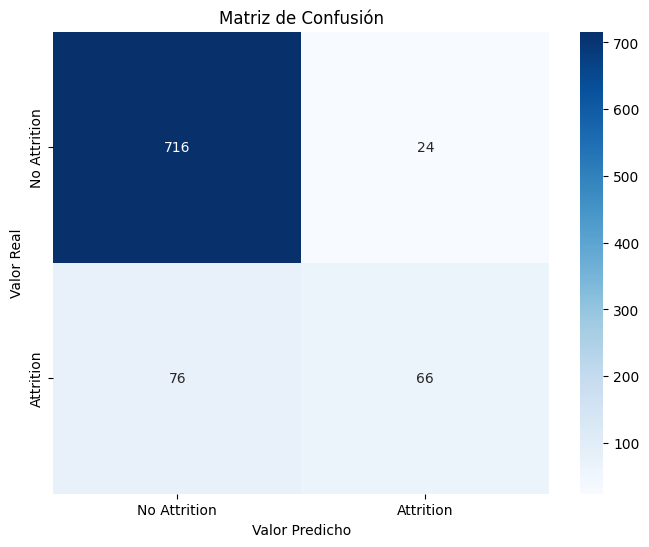

In [ ]:
#EVALUAR EL MODELO
#ATTRITION = ABANDONA
metrics_score(y_test, y_pred_test, labels=['No Attrition', 'Attrition'])


- El modelo tiene Accuracy = 0.89, que inicialmente parece muy buena.
- Sin embargo, para Attrition tiene Recall = 0.46: solamente identifica 66 de los 142 empleados que realmente abandonan y deja escapar 76.
- Es un excelente ejemplo de por qué Accuracy por sí sola puede ser engañosa en clases desbalanceadas.

In [ ]:
#COEFICIENTES PARA LA CLASE OBJETIVO (0)
lg.coef_df = pd.DataFrame(lg.coef_, columns=X.columns).T.sort_values(by=0, ascending=False)
lg.coef_df

,0
OverTime,0.959813
BusinessTravel_Travel_Frequently,0.715594
MaritalStatus_Single,0.612941
YearsSinceLastPromotion,0.548358
YearsAtCompany,0.518351
NumCompaniesWorked,0.499555
Department_Research & Development,0.443697
BusinessTravel_Travel_Rarely,0.440205
Department_Sales,0.436376
JobRole_Sales Executive,0.397936


In [ ]:
#RAZON DE PROBABILIDAD
# odd > 1 aumenta la probabilidad de desercion
# odd < 1 disminuye la probabilidad de desercion
# odd = 1 sin efecto
lg_odd_ratio = pd.DataFrame(np.exp(lg.coef_), columns=X.columns).T.sort_values(by=0, ascending=False)
lg_odd_ratio

,0
OverTime,2.611209
BusinessTravel_Travel_Frequently,2.045400
MaritalStatus_Single,1.845852
YearsSinceLastPromotion,1.730410
YearsAtCompany,1.679255
NumCompaniesWorked,1.647989
Department_Research & Development,1.558459
BusinessTravel_Travel_Rarely,1.553026
Department_Sales,1.547090
JobRole_Sales Executive,1.488748


(0.0, 1.0)

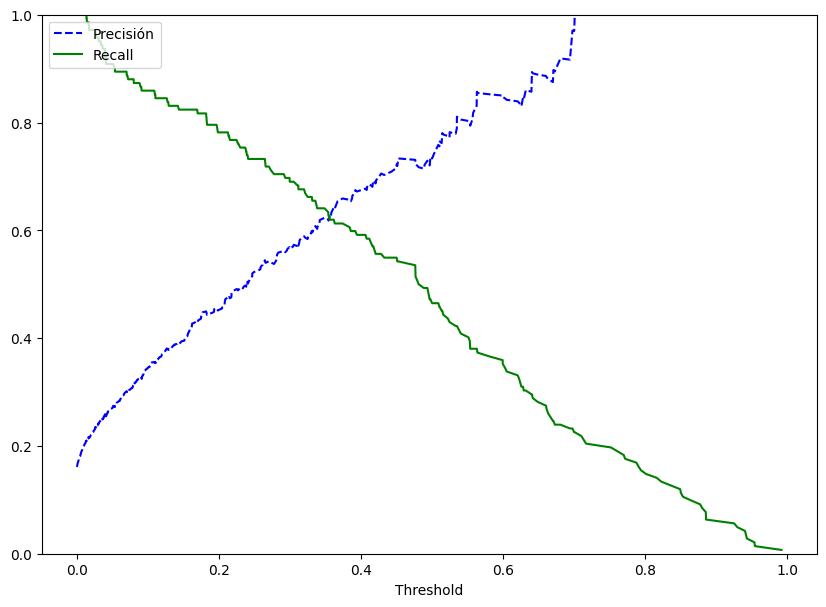

In [ ]:
#Curva Precision Recall
y_scores_lg = y_prob_test
preciscions_lg, recalls_lg, thresholds_lg = precision_recall_curve(y_test, y_scores_lg[:,1])

#Graficar la curva Precision Recall
plt.figure(figsize=(10,7))
plt.plot(thresholds_lg, preciscions_lg[:-1], "b--", label="Precisión")
plt.plot(thresholds_lg, recalls_lg[:-1], "g-", label="Recall")
plt.xlabel("Threshold")
plt.legend(loc="upper left")
plt.ylim([0,1])


Reporte de clasificación:
              precision    recall  f1-score   support

No Attrition       0.94      0.87      0.91       740
   Attrition       0.53      0.73      0.61       142

    accuracy                           0.85       882
   macro avg       0.73      0.80      0.76       882
weighted avg       0.88      0.85      0.86       882


Matriz de confusión:
[[646  94]
 [ 38 104]]


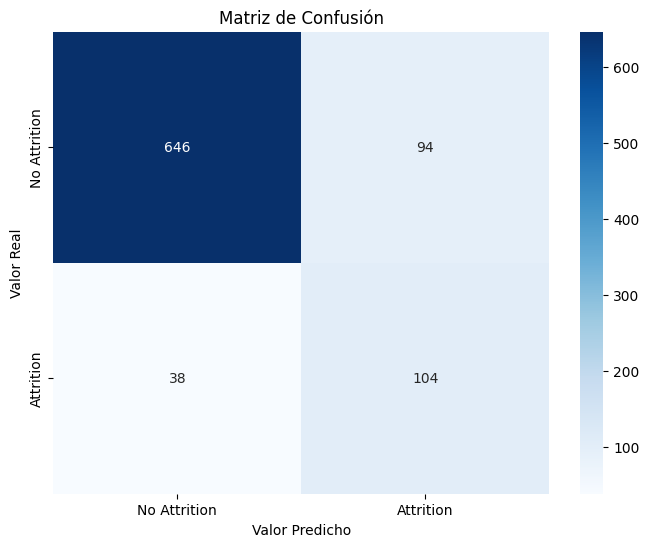

In [ ]:
optimo = 0.25
y_pred_test_optimo = lg.predict_proba(X_test_scaled)[:,1] >= optimo
metrics_score(y_test, y_pred_test_optimo, labels=['No Attrition', 'Attrition'])


- Bajar el umbral → aumenta TP → disminuye FN → aumenta Recall → pero también aumenta FP.

* Clasificamos como Attrition cuando la probabilidad estimada por el modelo es ≥ 0.35, en lugar de utilizar el umbral predeterminado de 0.50.
* Buscamos reducir los falsos negativos y aumentar la detección de empleados en riesgo, aceptando como consecuencia un incremento de falsos positivos.

# ARBOL DE DECISION

In [ ]:
dt = DecisionTreeClassifier(
    class_weight={0:0.17, 1:0.83},
    criterion='gini',
    min_samples_leaf = 10,
    min_impurity_decrease = 0.001,
    #max_depth = 5,
    random_state=42
)
dt.fit(X_train_scaled, y_train)

DecisionTreeClassifier(class_weight={0: 0.17, 1: 0.83},
                       min_impurity_decrease=0.001, min_samples_leaf=10,
                       random_state=42)

In [ ]:
print("PROFUNDIDAD DEL ARBOL", dt.get_depth())
print("NUMERO DE NODOS", dt.get_n_leaves())

PROFUNDIDAD DEL ARBOL 16
NUMERO DE NODOS 68



Reporte de clasificación:
              precision    recall  f1-score   support

No Attrition       0.96      0.81      0.88       740
   Attrition       0.45      0.81      0.58       142

    accuracy                           0.81       882
   macro avg       0.70      0.81      0.73       882
weighted avg       0.88      0.81      0.83       882


Matriz de confusión:
[[599 141]
 [ 27 115]]


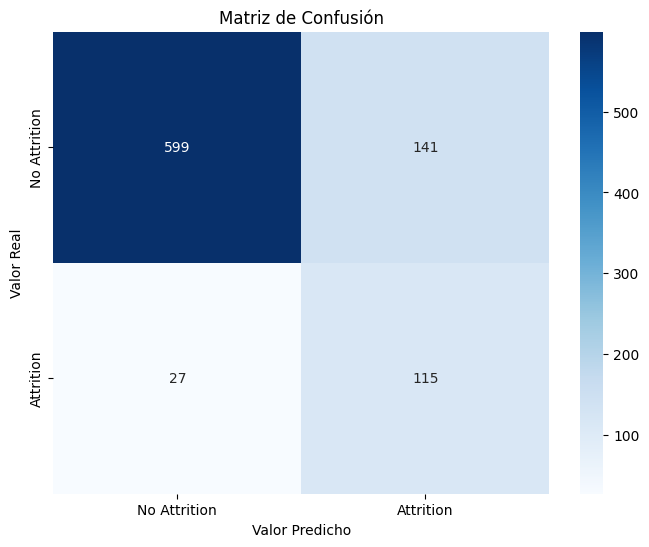

In [ ]:
y_pred_test = dt.predict(X_test_scaled)
metrics_score(y_test, y_pred_test, labels=['No Attrition', 'Attrition'])


In [ ]:
#Graficar las importancia de las variables y ver cuales son las mas importante
importances = pd.DataFrame({'feature':X.columns,'importance':np.round(dt.feature_importances_,3)})
importances = importances.sort_values('importance',ascending=False).set_index('feature')
importances

,importance
feature,
OverTime,0.156
MonthlyIncome,0.110
TotalWorkingYears,0.083
Age,0.081
NumCompaniesWorked,0.052
MonthlyRate,0.039
WorkLifeBalance,0.037
HourlyRate,0.036
YearsInCurrentRole,0.033


- De acuerdo con el árbol de decisión, **Overtime es la característica más importante, seguida de monthly income, Age, total working years, y MonthlyRate.**
- Esto podría significar que las personas que están en riesgo de abandono tienen bajos ingresos, están haciendo horas extras y tienen menos experiencia.
- Las otras características importantes son `DailyRate`, `NumCompaniesWorked`, `JobRole_Sales Executive` y `PercentSalaryHike`.

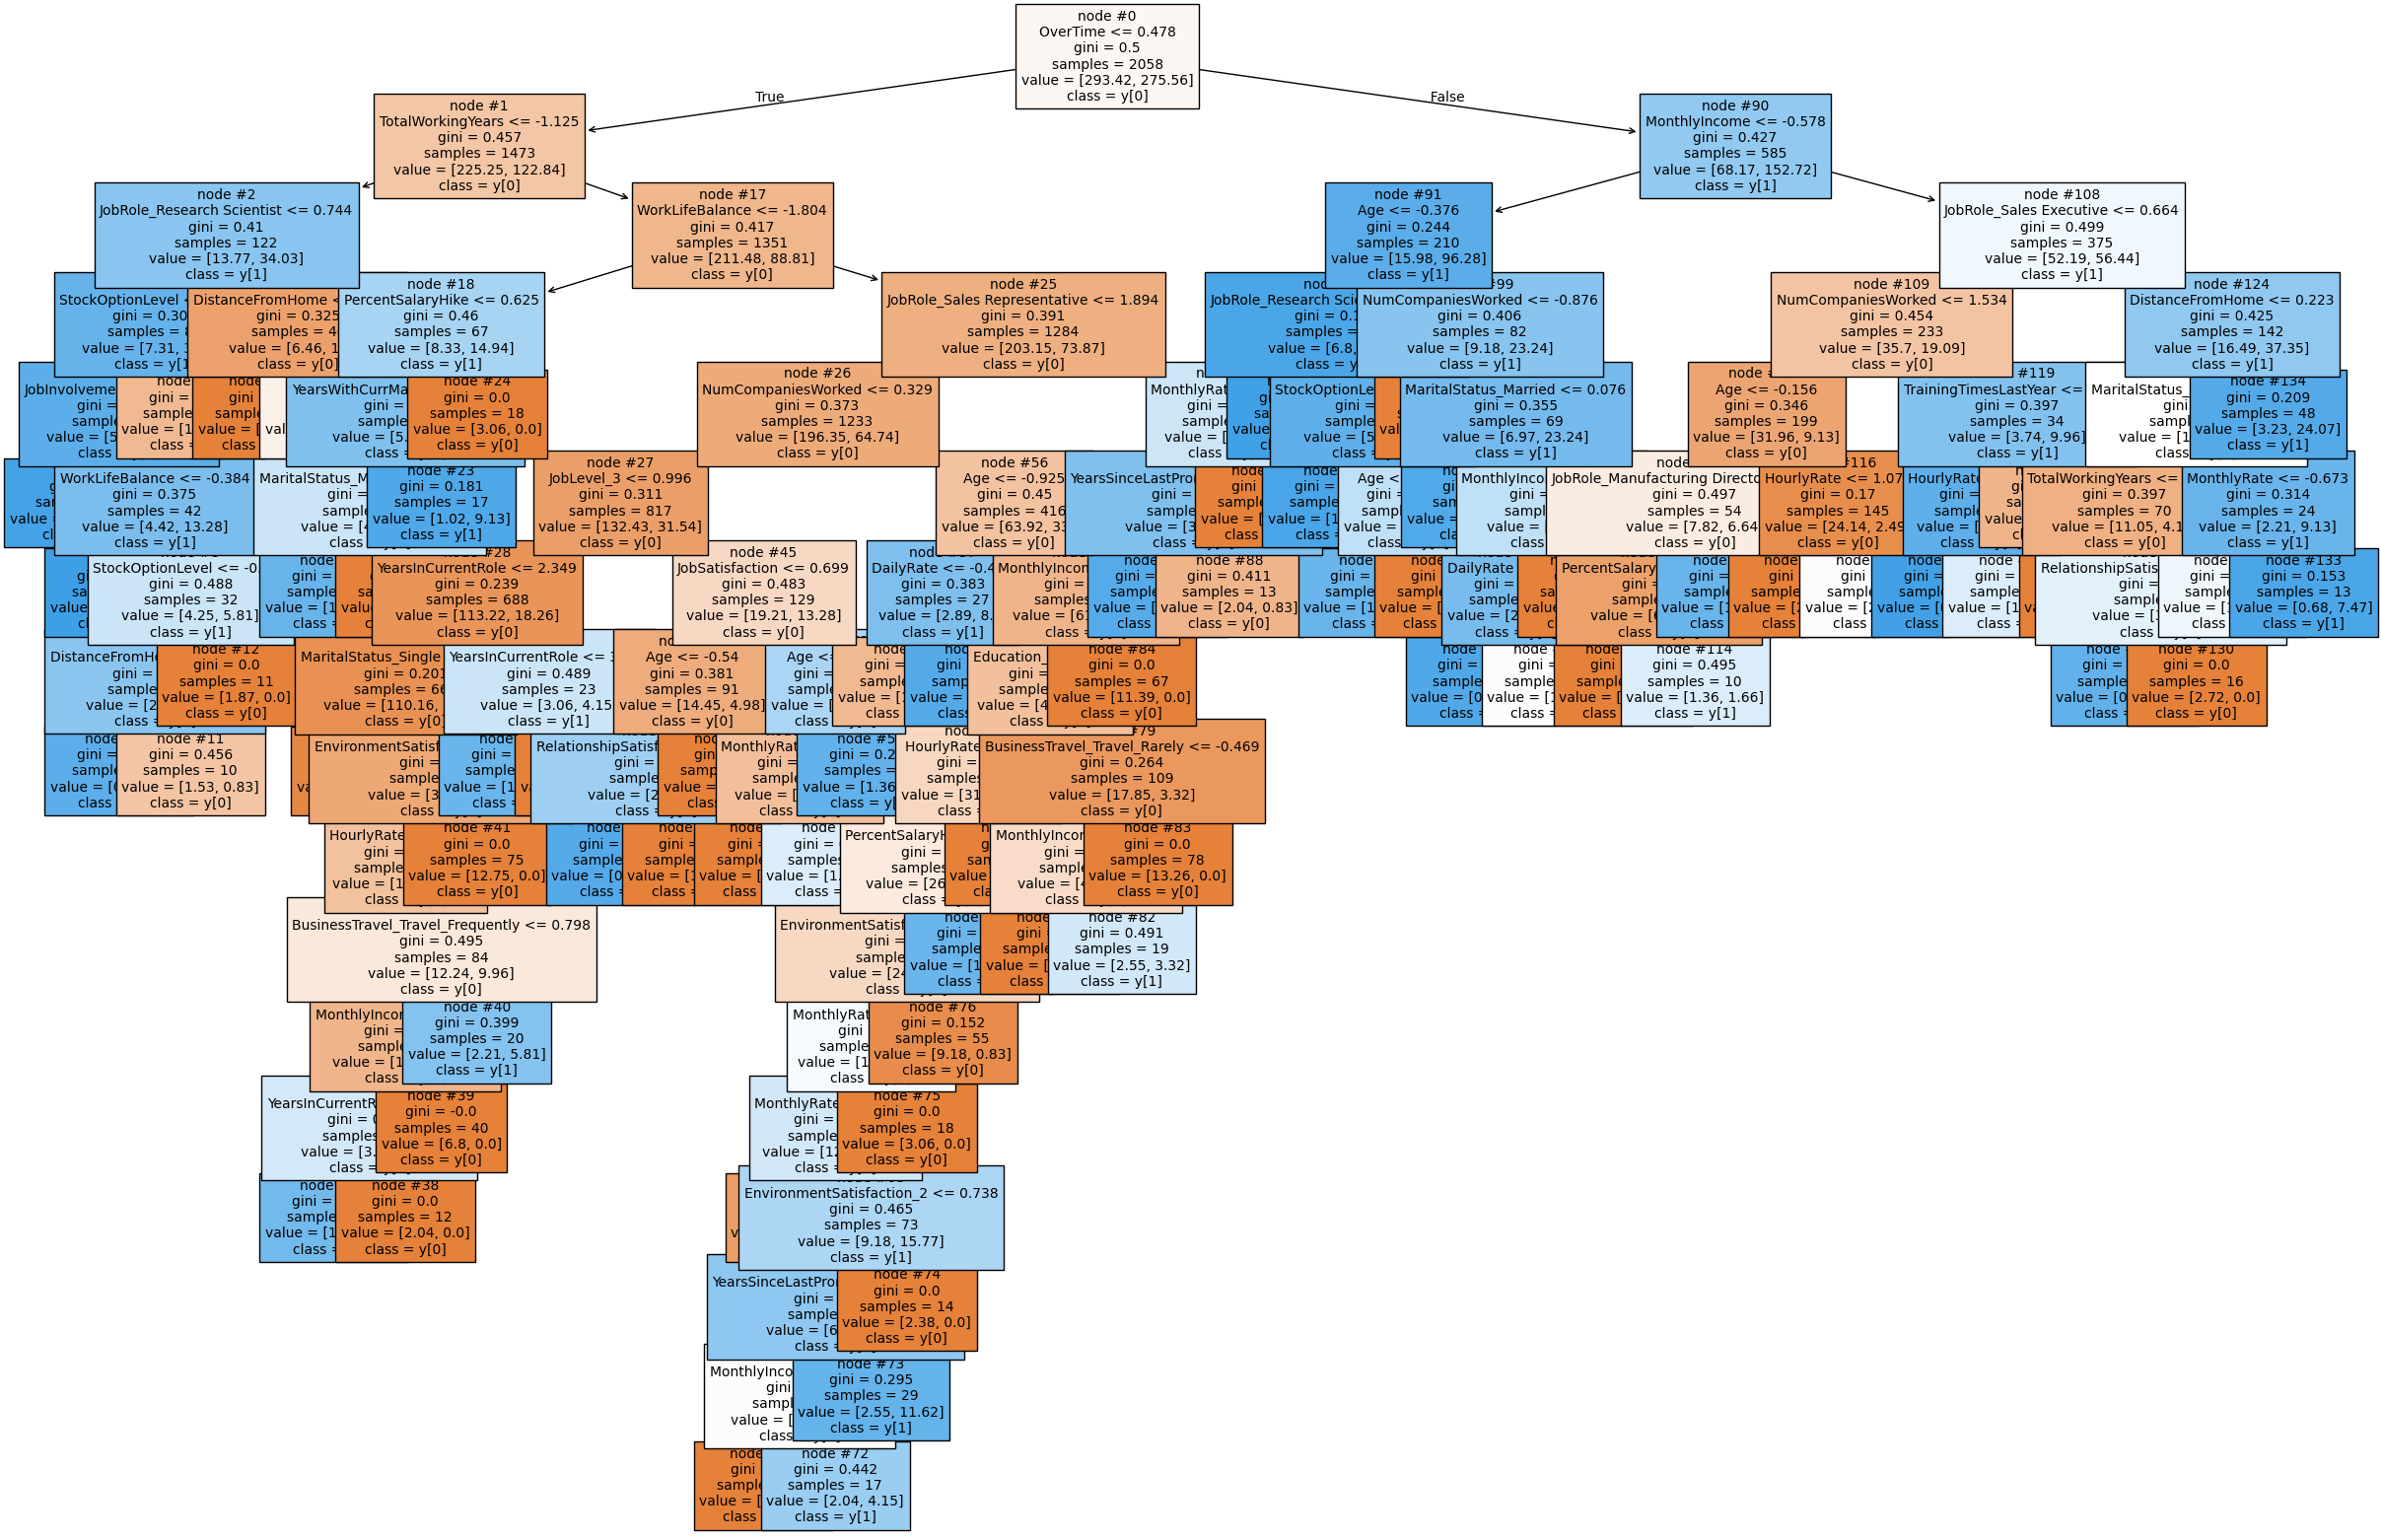

In [ ]:
#Graficar el arbol de decision
feature_names = X_train.columns
plt.figure(figsize=(30,20))
tree.plot_tree(dt, feature_names=feature_names, filled=True, fontsize=10,  class_names=True, node_ids=True)
plt.show()

# MAQUINA DE VECTORES DE SOPORTE (SVM)

##Maquina de vectores de soporte
* Los modelos de Máquinas de Vectores de Soporte (SVM) son clasificadores potentes que separan las clases buscando una frontera óptima. Sin embargo, no todos los problemas son lineales

### ¿Qué es un Kernel?
Un kernel es una función matemática que permite proyectar los datos a un espacio de mayor dimensión, donde es más fácil encontrar una frontera de separación entre clases.

1. **Kernel lineal**
* Supone que las clases pueden separarse con una línea recta.
2. **Kernel RBF (Radial Basis Function)**
* Permite generar fronteras curvas y flexibles, adaptándose a distribuciones más complejas.

In [ ]:
# Función para graficar los límites de decisión
def plot_svm(model, X, y, ax, title):
    h = .02
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.4, cmap=plt.cm.coolwarm)
    ax.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap=plt.cm.coolwarm)
    ax.set_title(title)
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())

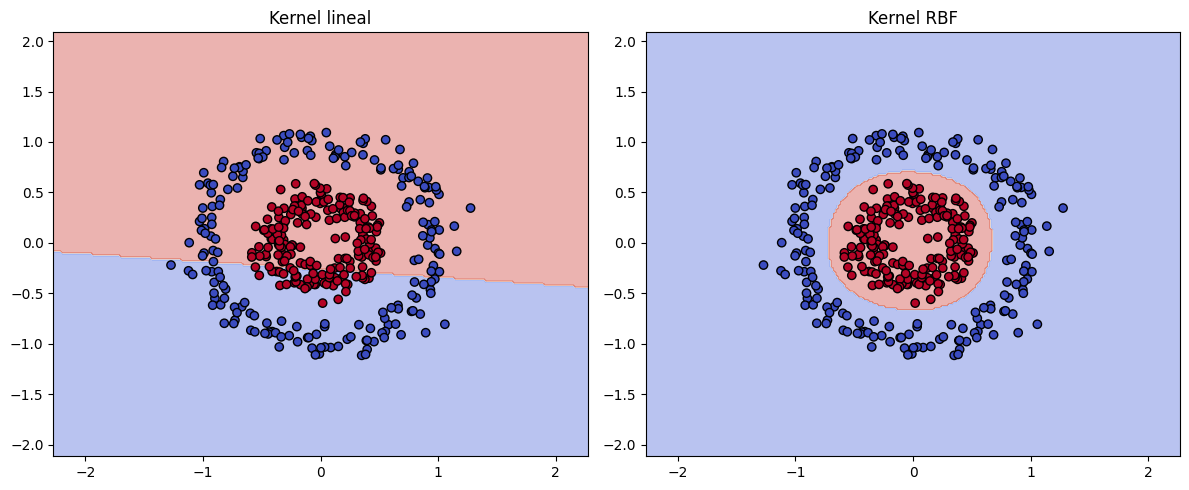

In [ ]:
from sklearn.datasets import make_circles

X_circ, y_circ = make_circles(n_samples=400, noise=0.1, factor=0.4, random_state=1)

#Entrenar SVM con kernel linal y RBF
svm_lin = SVC(kernel='linear').fit(X_circ, y_circ)
svm_rbf = SVC(kernel='rbf').fit(X_circ, y_circ)

#Grafica
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
plot_svm(svm_lin, X_circ, y_circ, axs[0], 'Kernel lineal')
plot_svm(svm_rbf, X_circ, y_circ, axs[1], 'Kernel RBF')
plt.tight_layout()
plt.show()

In [ ]:
svm = SVC(kernel='linear')
svm.fit(X_train_scaled, y_train)

SVC(kernel='linear')


Reporte de clasificación:
              precision    recall  f1-score   support

No Attrition       0.90      0.97      0.94       740
   Attrition       0.76      0.44      0.56       142

    accuracy                           0.89       882
   macro avg       0.83      0.71      0.75       882
weighted avg       0.88      0.89      0.88       882


Matriz de confusión:
[[720  20]
 [ 79  63]]


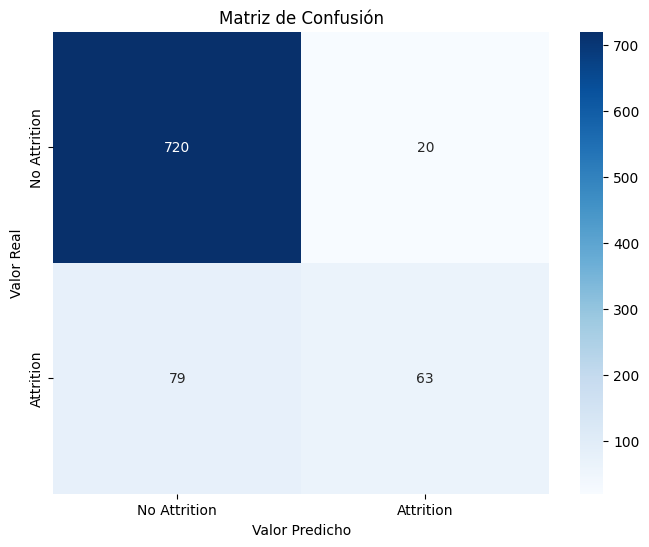

In [ ]:
y_pred_test_svm_lin = svm.predict(X_test_scaled)
metrics_score(y_test, y_pred_test_svm_lin, labels=['No Attrition', 'Attrition'])

# BOSQUE ALEATORIO (Random Forest)

In [ ]:
rf = RandomForestClassifier(
    class_weight = {0: 0.17, 1: 0.83},
    random_state=1,
    criterion='gini',
    min_samples_leaf = 3,
    min_impurity_decrease = 0.001,
    n_estimators = 100
)
rf.fit(X_train_scaled, y_train)

RandomForestClassifier(class_weight={0: 0.17, 1: 0.83},
                       min_impurity_decrease=0.001, min_samples_leaf=3,
                       random_state=1)

In [ ]:
print("NUMERO DE ESTIMADORES", rf.n_estimators)
print("PROFUNDIDAD DEL ARBOL", rf.max_depth)

NUMERO DE ESTIMADORES 100
PROFUNDIDAD DEL ARBOL None



Reporte de clasificación:
              precision    recall  f1-score   support

No Attrition       0.95      0.96      0.96       740
   Attrition       0.79      0.73      0.75       142

    accuracy                           0.92       882
   macro avg       0.87      0.84      0.85       882
weighted avg       0.92      0.92      0.92       882


Matriz de confusión:
[[712  28]
 [ 39 103]]


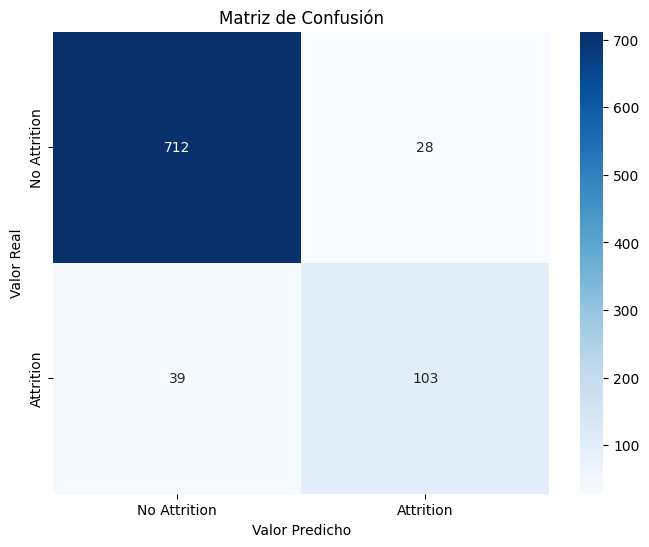

In [ ]:
y_pred_test_rf = rf.predict(X_test_scaled)
metrics_score(y_test, y_pred_test_rf, labels=['No Attrition', 'Attrition'])

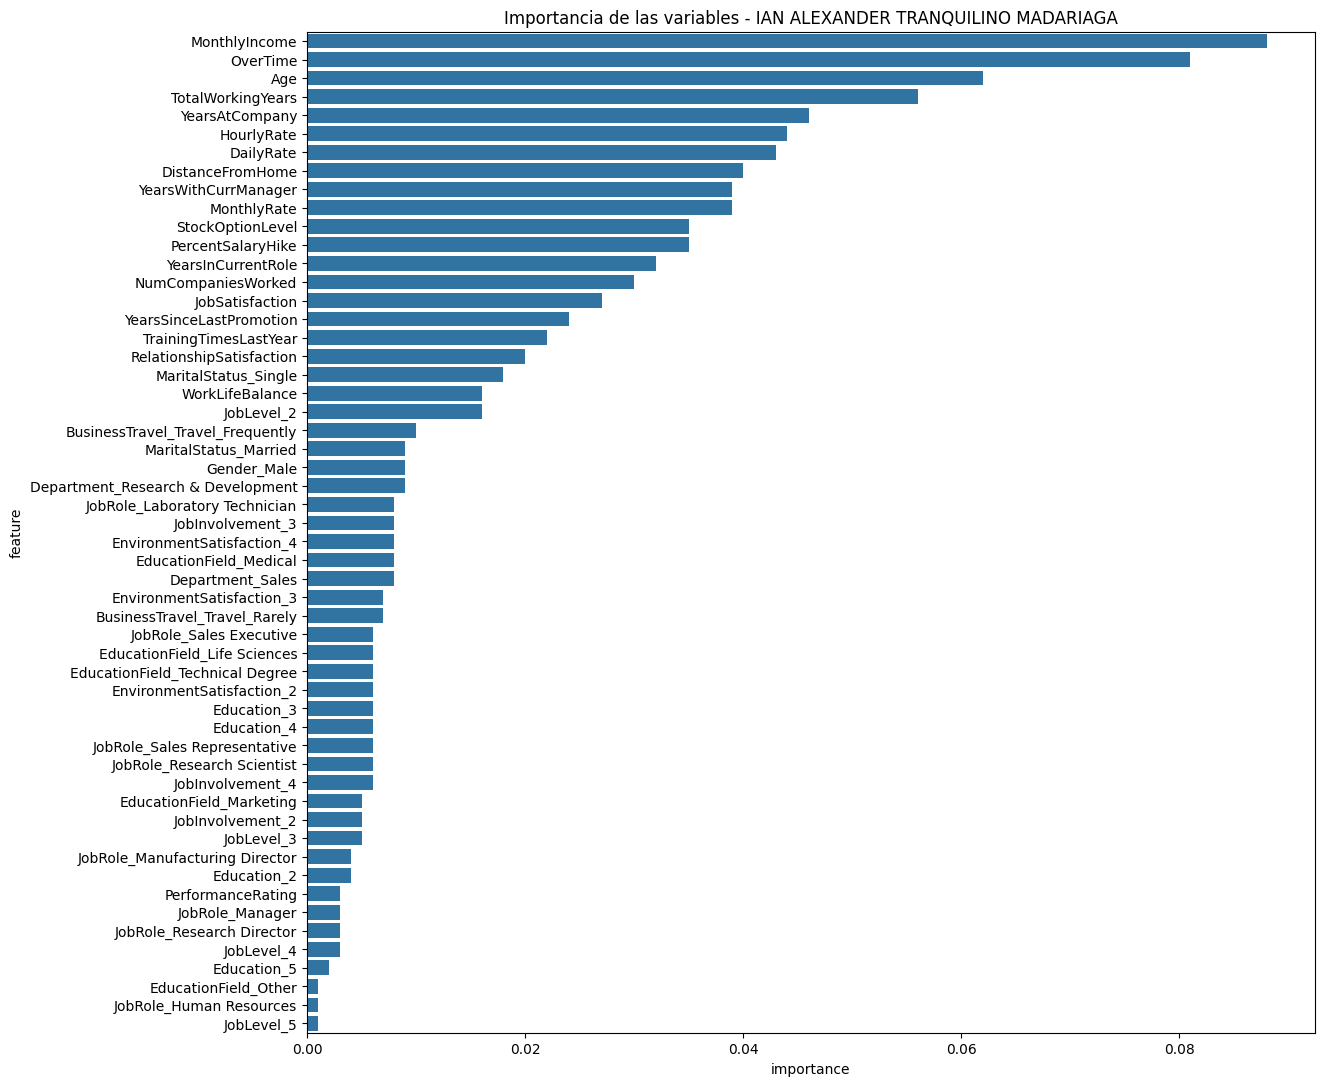

In [ ]:
rf_importances = pd.DataFrame({'feature':X.columns,'importance':np.round(rf.feature_importances_,3)})
rf_importances = rf_importances.sort_values('importance',ascending=False).set_index('feature')

plt.figure(figsize=(13,13))
sns.barplot(y=rf_importances.index, x=rf_importances['importance'])
plt.title("Importancia de las variables - IAN ALEXANDER TRANQUILINO MADARIAGA")
# plt.xticks(rotation=90)
plt.show()